# Model Training and Evaluation

## Objective

Evaluate whether machine-learning models can distinguish healthy controls, bipolar disorder, and schizophrenia using gene-expression profiles, using established classification models with no feature selection.

## Models

- Dummy classifier baseline
- Logistic regression
- K-nearest neighbours (KNN)
- Random forest

## Workflow

1. Load the cleaned dataset and create a stratified train/test split.
2. Compare models using five-fold stratified cross-validation.
3. Evaluate initial models on the held-out test set.
4. Tune hyperparameters using training data only.
5. Evaluate the selected models on the held-out test set.
6. Compare model performance and inspect confusion matrices.

The dataset contains 87 samples and 30,635 gene-expression features. The small sample size relative to the number of features makes overfitting a major concern.

The test set is reserved for final evaluation. Preprocessing, cross-validation, and hyperparameter selection use training data only.

## Import Libraries and Set Up Paths
Import the libraries required for data preparation, model training, cross-validation, hyperparameter tuning, and evaluation. Define the project paths and random seed.

In [1]:
from pathlib import Path

import pandas as pd
import matplotlib.pyplot as plt

from sklearn.dummy import DummyClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import (
    train_test_split,
    StratifiedKFold,
    cross_val_score,
    GridSearchCV,
)
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import (
    accuracy_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)

RANDOM_STATE = 42

PROJECT_DIR = Path.cwd().parent
PROCESSED_DIR = PROJECT_DIR / "data" / "processed"

print("Imports successful.")
print("Project directory:", PROJECT_DIR)

Imports successful.
Project directory: C:\Users\taraj\OneDrive\Documents\GitHub\psychiatric-gene-expression-ml


## Load Data and Create a Stratified Train/Test Split
Load the cleaned expression matrix and sample metadata, align diagnosis labels with the expression profiles, and create a reproducible stratified train/test split. Check that each sample is paired with the correct label and that training and test samples do not overlap.

In [2]:
X = pd.read_csv(
    PROCESSED_DIR / "expression_matrix.csv",
    index_col=0,
)

metadata_clean = pd.read_csv(
    PROCESSED_DIR / "sample_metadata.csv",
)

X.index = X.index.astype(str)
metadata_clean["sample_id"] = metadata_clean["sample_id"].astype(str)

# Align diagnosis labels with the expression matrix.
metadata_indexed = metadata_clean.set_index("sample_id")
y = metadata_indexed.loc[X.index, "disease state"]

assert X.index.equals(y.index)
assert y.notna().all()

# Create a reproducible, stratified split.
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=RANDOM_STATE,
    stratify=y,
)

assert set(X_train.index).isdisjoint(X_test.index)
assert X_train.index.equals(y_train.index)
assert X_test.index.equals(y_test.index)

print("Full dataset:", X.shape)
print("Training set:", X_train.shape)
print("Test set:", X_test.shape)

print("\nTraining classes:")
print(y_train.value_counts())

print("\nTest classes:")
print(y_test.value_counts())

Full dataset: (87, 30635)
Training set: (69, 30635)
Test set: (18, 30635)

Training classes:
disease state
bipolar disorder    23
schizophrenia       23
healthy control     23
Name: count, dtype: int64

Test classes:
disease state
schizophrenia       6
healthy control     6
bipolar disorder    6
Name: count, dtype: int64


## Define Baseline and Candidate Models
Define a dummy classifier, logistic regression, KNN, and random forest as the initial candidate models. Use pipelines to handle missing expression values within each training fold, and scale features for models that depend on feature magnitudes.

In [3]:
models = {
    "Dummy baseline": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", DummyClassifier(strategy="most_frequent")),
    ]),
    "Logistic regression": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", LogisticRegression(
            max_iter=2000,
            class_weight="balanced",
            random_state=RANDOM_STATE,
        )),
    ]),
    "KNN": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("scaler", StandardScaler()),
        ("classifier", KNeighborsClassifier(n_neighbors=5)),
    ]),
    "Random forest": Pipeline([
        ("imputer", SimpleImputer(strategy="median")),
        ("classifier", RandomForestClassifier(
            n_estimators=200,
            class_weight="balanced",
            random_state=RANDOM_STATE,
            n_jobs=-1,
        )),
    ]),
}

print("Models defined:")
for name in models:
    print("-", name)

Models defined:
- Dummy baseline
- Logistic regression
- KNN
- Random forest


## 5-fold stratified cross-validation
Compare the initial models using five-fold stratified cross-validation on the training set. Use macro F1-score to give equal importance to each diagnosis class, and report the mean and standard deviation across folds.

In [4]:
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=RANDOM_STATE,
)

cv_results = []

for name, model in models.items():
    scores = cross_val_score(
        model,
        X_train,
        y_train,
        cv=cv,
        scoring="f1_macro",
        n_jobs=1,
    )

    cv_results.append({
        "Model": name,
        "Mean CV macro F1": scores.mean(),
        "Std CV macro F1": scores.std(),
    })

cv_results_df = (
    pd.DataFrame(cv_results)
    .sort_values("Mean CV macro F1", ascending=False)
    .reset_index(drop=True)
)

cv_results_df

,Model,Mean CV macro F1,Std CV macro F1
1,Logistic regression,0.398451,0.077292
3,Random forest,0.307542,0.088247
2,KNN,0.283350,0.086826
0,Dummy baseline,0.149891,0.003486


## Cross-Validation Results
The initial models were compared using five-fold stratified cross-validation on the training set, with macro F1-score as the selection metric.

The mean score provides an estimate of performance across folds, while the standard deviation indicates how much performance varies between folds. These estimates help compare candidate models, but they may be uncertain because the dataset is small and contains many features.

Logistic regression achieved the highest mean macro F1-score (0.398), followed by random forest (0.308) and KNN (0.283). The dummy baseline achieved a mean macro F1-score of 0.150.

These results suggest that logistic regression is the strongest candidate among the evaluated models. However, the small dataset and variation across folds limit the conclusions that can be drawn. Final performance will be assessed on the held-out test set, which was not used for model selection.

## Test Set Evaluation
Fit each initial model on the full training set and evaluate its predictions on the held-out test set. Record accuracy and macro F1-score for comparison with the tuned models.

In [5]:

test_results = []
test_predictions = {}

for name, model in models.items():
    model.fit(X_train, y_train)

    y_pred = model.predict(X_test)
    test_predictions[name] = y_pred

    test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    })

test_results_df = (
    pd.DataFrame(test_results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(test_results_df.round(3))

,Model,Accuracy,Macro F1
1,Logistic regression,0.444444,0.433333
2,KNN,0.388889,0.405526
3,Random forest,0.277778,0.261586
0,Dummy baseline,0.333333,0.166667


## Hyperparameter Tuning
Tune logistic regression, KNN, and random forest using stratified cross-validation on the training set. Select hyperparameters using macro F1-score, giving equal weight to each diagnosis class

In [6]:
param_grids = {
    "Logistic regression": {
        "classifier__C": [0.01, 0.1, 1.0, 10.0],
    },
    "KNN": {
        "classifier__n_neighbors": [3, 5, 7, 9],
        "classifier__weights": ["uniform", "distance"],
    },
    "Random forest": {
        "classifier__n_estimators": [100, 200],
        "classifier__max_depth": [None, 5, 10],
        "classifier__min_samples_leaf": [1, 2],
    },
}

grid_searches = {}
tuning_results = []

for name, param_grid in param_grids.items():
    search = GridSearchCV(
        estimator=models[name],
        param_grid=param_grid,
        scoring="f1_macro",
        cv=cv,
        n_jobs=-1,
        refit=True,
    )

    search.fit(X_train, y_train)
    grid_searches[name] = search

    tuning_results.append({
        "Model": name,
        "Best CV macro F1": search.best_score_,
        "Best parameters": search.best_params_,
    })

tuning_results_df = (
    pd.DataFrame(tuning_results)
    .sort_values("Best CV macro F1", ascending=False)
    .reset_index(drop=True)
)

display(tuning_results_df)

,Model,Best CV macro F1,Best parameters
0,Logistic regression,0.398451,{'classifier__C': 1.0}
1,KNN,0.338285,"{'classifier__n_neighbors': 9, 'classifier__we..."
2,Random forest,0.331514,"{'classifier__max_depth': None, 'classifier__m..."


## Retrieve the Best Models
Retrieve the best estimator selected by cross-validated hyperparameter tuning for each candidate model. These estimators use the parameter settings selected by GridSearchCV rather than manually specified values.

In [8]:
tuned_models = {
    name: search.best_estimator_
    for name, search in grid_searches.items()
}

print("Selected models:")
for name, model in tuned_models.items():
    print(f"{name}: {model.named_steps['classifier']}")

Tuned models defined:

Logistic regression
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 LogisticRegression(class_weight='balanced', max_iter=2000,
                                    random_state=42))])

KNN
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('scaler', StandardScaler()),
                ('classifier',
                 KNeighborsClassifier(n_neighbors=9, weights='distance'))])

Random forest
Pipeline(steps=[('imputer', SimpleImputer(strategy='median')),
                ('classifier',
                 RandomForestClassifier(class_weight='balanced', n_jobs=-1,
                                        random_state=42))])


## Evaluate the Selected Models on the Test Set
Evaluate the selected models on the held-out test set and record accuracy and macro F1-score. The models were fitted on the training set during GridSearchCV.

In [9]:
tuned_test_results = []
tuned_test_predictions = {}

for name, model in tuned_models.items():
    y_pred = model.predict(X_test)
    tuned_test_predictions[name] = y_pred

    tuned_test_results.append({
        "Model": name,
        "Accuracy": accuracy_score(y_test, y_pred),
        "Macro F1": f1_score(
            y_test,
            y_pred,
            average="macro",
            zero_division=0,
        ),
    })

tuned_test_results_df = (
    pd.DataFrame(tuned_test_results)
    .sort_values("Macro F1", ascending=False)
    .reset_index(drop=True)
)

display(tuned_test_results_df.round(3))

,Model,Accuracy,Macro F1
0,Logistic regression,0.444,0.433
1,KNN,0.389,0.371
2,Random forest,0.333,0.345


## Confusion Matrices
Plot confusion matrices for the selected models using their predictions on the held-out test set. These matrices show which diagnosis classes are correctly identified and which are confused with one another.

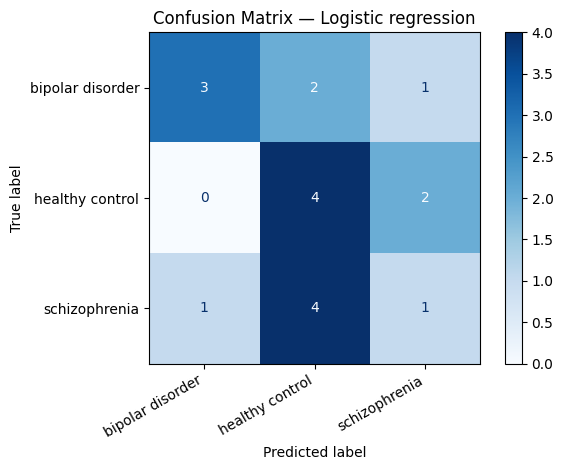

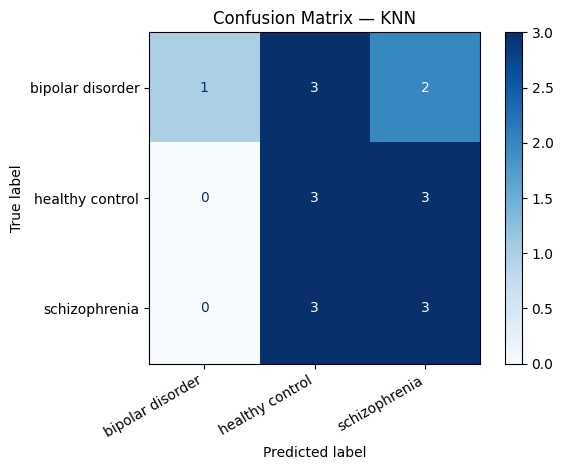

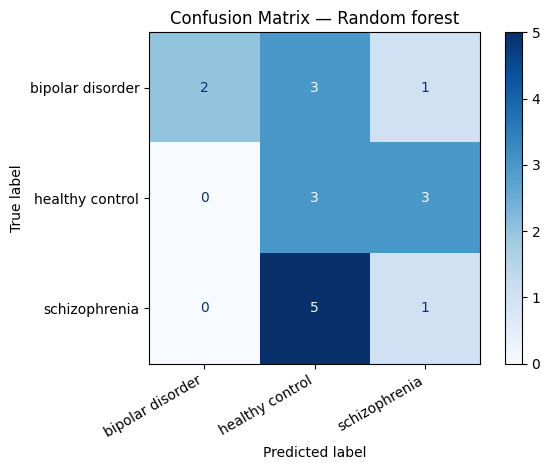

In [10]:
class_labels = sorted(y.unique())

for name, y_pred in tuned_test_predictions.items():
    cm = confusion_matrix(
        y_test,
        y_pred,
        labels=class_labels,
    )

    disp = ConfusionMatrixDisplay(
        confusion_matrix=cm,
        display_labels=class_labels,
    )

    disp.plot(cmap="Blues", values_format="d")
    plt.title(f"Confusion Matrix — {name}")
    plt.xticks(rotation=30, ha="right")
    plt.tight_layout()
    plt.show()

## Tuned Model Evaluation
The selected models were evaluated on the held-out test set using accuracy and macro F1-score.

Macro F1-score gives equal weight to each diagnosis class, making it useful when evaluating multiclass classification performance. The confusion matrices provide additional detail about which classes each model identifies correctly and where misclassifications occur.

The test set contains only 18 samples, so each prediction has a substantial effect on the reported metrics.

Logistic regression achieved the highest accuracy (44.4%) and macro F1-score (0.433), followed by KNN (38.9% accuracy; macro F1 0.371) and random forest (33.3% accuracy; macro F1 0.345).

The confusion matrices show that all three models misclassified multiple samples. Logistic regression performed best overall but had particular difficulty identifying schizophrenia samples. These results suggest limited classification performance on this small test set and do not establish reliable diagnostic discrimination.

The results should be interpreted cautiously because the dataset contains only 87 samples, with 18 reserved for testing. Further investigation using dimensionality reduction may help determine whether a smaller feature representation improves classification, but improvement is not guaranteed.